# Discrete Mathematics: Combinatorics and Recurrences

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising counting, recurrences and generating functions (part of *Discrete Structures* in BS AI / BS CS / BS Data Science) for an exam or interview.
>
> **What you will learn**
> - The **sum, product, subtraction and division rules**, the basis of all counting
> - **Permutations** and **combinations**, with and without repetition (including "stars and bars"), each checked against `itertools`
> - The **binomial theorem**, **Pascal's triangle**, binomial identities and **multinomial** coefficients
> - The **pigeonhole principle**, the **birthday paradox** (simulated) and why **hash collisions** are unavoidable
> - **Inclusion–exclusion**, with **derangements** and **counting surjections**
> - **Recurrence relations**: modelling problems with them and solving linear homogeneous recurrences with the **characteristic-root method** (distinct and repeated roots), checked numerically; fast Fibonacci with matrix powers
> - **Generating functions**: counting by multiplying polynomials (coin change, dice), and reading a recurrence off a power series
> - **Catalan numbers** and **Stirling numbers** (binary trees, bracketings, set partitions, cycles)
> - Why **combinatorial explosion** makes grid search, brute-force feature selection and exhaustive game search infeasible
>
> **Prerequisites:** [`01_sets_relations_functions_and_proofs.ipynb`](01_sets_relations_functions_and_proofs.ipynb) (sets, functions, induction). Helpful: [`dsa/01_complexity_analysis_and_recursion.ipynb`](../../00_AI_Fundamentals/dsa/01_complexity_analysis_and_recursion.ipynb) (recursion, the Master theorem) and [`14_Mathematics/03_probability.ipynb`](../03_probability.ipynb) (basic probability).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, numpy, pandas, matplotlib. The notebook runs in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Rosen, *Discrete Mathematics and Its Applications* (8th ed.), chapters 6 and 8, and Graham, Knuth and Patashnik, *Concrete Mathematics* (2nd ed.), chapters 5–7.

## Explained simply

Combinatorics is the art of **counting without listing**. If a café offers 3 breads, 4 fillings and 2 sauces, you do not need to write out every sandwich to know there are 3 × 4 × 2 = 24. That matters because the things AI engineers count (settings to try, word sequences, moves in a game) quickly become so many that listing them would take longer than the age of the universe. A **recurrence** describes a count in terms of smaller counts, like "the number of ways to climb 10 stairs is the ways to climb 9 plus the ways to climb 8". Solving the recurrence turns that step-by-step rule into a direct formula. Together they tell you, before you write any code, whether brute force is hopeless.

**Everyday examples.**
- A 4-digit phone PIN has 10 × 10 × 10 × 10 = 10,000 possibilities, so a thief guessing at random has a 1 in 10,000 chance per try.
- In a class of 23 students there is about a 50% chance that two share a birthday. It feels too high, but there are 253 *pairs* of students, and each pair is a chance for a match.
- Rabbits, savings with interest, and the number of ways to tile a path all grow by "the next value depends on the previous ones" rules: recurrences.

**A tiny example.** You have 3 T-shirts and 2 pairs of jeans. Outfits: 3 × 2 = **6**. If you choose 2 of your 3 T-shirts to pack for a trip, order does not matter: {red, blue}, {red, green}, {blue, green}, so **3** ways, which is "3 choose 2". If instead you decide which T-shirt to wear on Monday and which on Tuesday, order matters: 3 × 2 = **6** ways.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Product rule, permutations, combinations | multiply the choices; divide out the orderings you do not care about | PINs and passwords; the size of a hyperparameter grid |
| Pigeonhole and birthday paradox | more items than boxes forces a shared box, and sooner than you think | shared birthdays; hash collisions in a database or a cache |
| Recurrences and generating functions | describe a count by smaller counts, then solve for a formula | compound interest; dynamic programming; counting parse trees |

### How this notebook relates to others
- [`01_sets_relations_functions_and_proofs`](01_sets_relations_functions_and_proofs.ipynb) counted relations and functions by brute force. Here we learn the general tools.
- [`dsa/01`](../../00_AI_Fundamentals/dsa/01_complexity_analysis_and_recursion.ipynb) solves **divide-and-conquer** recurrences $T(n) = aT(n/b) + f(n)$ with the Master theorem. Here we solve **linear** recurrences $a_n = c_1 a_{n-1} + \dots + c_k a_{n-k}$, the other big family. Section 7.4 puts the two side by side.
- [`dsa/09`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb) *computes* recurrences with dynamic programming; here we find closed forms.

## Table of contents
1. Sum, product, subtraction and division rules
2. Permutations and combinations
3. Binomial theorem, Pascal's triangle and multinomials
4. The pigeonhole principle and the birthday paradox
5. Inclusion–exclusion, derangements and surjections
6. Modelling with recurrence relations
7. Solving linear recurrences
8. Generating functions
9. Catalan and Stirling numbers
10. Summary of formulas
11. How this connects to modern AI: combinatorial explosion
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from itertools import product, permutations, combinations, combinations_with_replacement
from functools import lru_cache
from collections import Counter
import hashlib

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Sum, product, subtraction and division rules

> **In plain English:** count choices by adding when you pick one option *or* another, and multiplying when you pick one *and then* another.

**Intuition.** "Or" usually means add, "and then" usually means multiply.

| Rule | Statement | Example |
|---|---|---|
| **Sum rule** | if a task can be done in one of $n_1$ ways **or** one of $n_2$ ways, with no overlap, there are $n_1 + n_2$ ways | choose a project from list A (12) or list B (7): 19 ways |
| **Product rule** | if a task is a sequence of steps with $n_1$ ways **and then** $n_2$ ways (independent of the first choice), there are $n_1 \cdot n_2$ ways | 3 breads × 4 fillings × 2 sauces = 24 sandwiches |
| **Subtraction rule** (2-set inclusion–exclusion) | $\lvert A \cup B\rvert = \lvert A\rvert + \lvert B\rvert - \lvert A \cap B\rvert$ | bit strings of length 8 that start with 1 **or** end with 00: 128 + 64 − 32 = 160 |
| **Division rule** | if every outcome is counted exactly d times, divide by d | seat 5 people at a round table (rotations are the same): 5!/5 = 24 |

The product rule is the Cartesian product from notebook 01: $|A_1 \times \dots \times A_k| = |A_1| \cdots |A_k|$.

In [2]:
# Product rule: 8-character passwords from lowercase letters and digits
alphabet = 26 + 10
n_passwords = alphabet ** 8
print(f"8-char passwords over 36 symbols: {n_passwords:,}")
print(f"at 10 billion guesses per second, trying all takes {n_passwords / 1e10 / 60:.1f} minutes")

# Subtraction rule, checked by listing all 256 bit strings
strings = ["".join(bits) for bits in product("01", repeat=8)]
count = sum(1 for s in strings if s.startswith("1") or s.endswith("00"))
print("start with 1 or end with 00:", count, "| formula 128 + 64 - 32 =", 128 + 64 - 32)
assert count == 160

# Division rule: round-table seatings. Two seatings are the same if one is a rotation of the other.
def canonical_rotation(seating):
    """Rotate so that person 0 sits first; all rotations of a seating map to the same tuple."""
    i = seating.index(0)
    return seating[i:] + seating[:i]

tables = {canonical_rotation(p) for p in permutations(range(5))}
print("round-table seatings of 5 people:", len(tables), "| 5!/5 = (5-1)! =", math.factorial(4))
assert len(tables) == math.factorial(4)

8-char passwords over 36 symbols: 2,821,109,907,456
at 10 billion guesses per second, trying all takes 4.7 minutes
start with 1 or end with 00: 160 | formula 128 + 64 - 32 = 160
round-table seatings of 5 people: 24 | 5!/5 = (5-1)! = 24


**What just happened?** The password space of $36^8 \approx 2.8 \times 10^{12}$ falls to a fast attacker in under 5 minutes, which is why real password rules ask for length (each extra character multiplies the space by 36 or more). The subtraction and division rules matched the brute-force counts.

> ⚠️ **Common mistake:** using the product rule when the choices are **not independent** or overlap. "How many 2-letter strings have two *different* letters?" is 26 × 25, not 26 × 26, because the second choice depends on the first.

---
## 2. Permutations and combinations

> **In plain English:** permutations count arrangements where order matters; combinations count selections where it does not.

**Definitions.**
- An **r-permutation** of n distinct objects is an *ordered* arrangement of r of them. Count: $P(n, r) = n(n-1)\cdots(n-r+1) = \dfrac{n!}{(n-r)!}$ (product rule: n choices, then n − 1, …).
- An **r-combination** is an *unordered* selection of r of them. Count: $\binom{n}{r} = C(n, r) = \dfrac{n!}{r!\,(n-r)!}$. (Division rule: each combination appears as $r!$ permutations.)

**The four basic counting problems** ("choose r from n"):

| | order matters | order does not matter |
|---|---|---|
| **no repetition** | $\dfrac{n!}{(n-r)!}$ (podium of 3 from 8 runners) | $\dbinom{n}{r}$ (lottery ticket) |
| **repetition allowed** | $n^r$ (PIN codes) | $\dbinom{n+r-1}{r}$ (scoops of ice cream from n flavours) |

The bottom-right entry is **stars and bars**. Picking r items from n types with repetition is the same as arranging r stars and n − 1 bars in a row: the bars split the stars into n groups. Example: 3 scoops from {vanilla, chocolate, mango}:

```
★★|★|      = 2 vanilla, 1 chocolate, 0 mango
|★★★|      = 0 vanilla, 3 chocolate, 0 mango
★||★★      = 1 vanilla, 0 chocolate, 2 mango
```
A row has r + n − 1 symbols and we choose which r are stars: $\binom{n+r-1}{r} = \binom{5}{3} = 10$.

**Permutations of a multiset.** The number of distinct arrangements of n items where item type i appears $n_i$ times is the **multinomial coefficient** $\dfrac{n!}{n_1!\,n_2!\cdots n_k!}$. MISSISSIPPI (1 M, 4 I, 4 S, 2 P) has $\frac{11!}{1!\,4!\,4!\,2!} = 34{,}650$ arrangements.

In [3]:
def gen_permutations(items, r):
    """All r-permutations, built recursively: pick a first item, then permute the rest."""
    if r == 0:
        return [()]
    out = []
    for i, x in enumerate(items):
        rest = items[:i] + items[i + 1:]                  # cannot reuse x
        out += [(x,) + p for p in gen_permutations(rest, r - 1)]
    return out

def gen_combinations(items, r):
    """All r-combinations: either include items[0] or skip it (Pascal's rule in code form)."""
    if r == 0:
        return [()]
    if len(items) < r:
        return []
    first, rest = items[0], items[1:]
    return [(first,) + c for c in gen_combinations(rest, r - 1)] + gen_combinations(rest, r)

items = list("ABCDEF")
rows = []
for r in range(0, 5):
    perms, combs = gen_permutations(items, r), gen_combinations(items, r)
    assert perms == list(permutations(items, r)) and combs == list(combinations(items, r))
    rows.append({"r": r,
                 "P(6,r) listed": len(perms), "6!/(6-r)!": math.perm(6, r),
                 "C(6,r) listed": len(combs), "C(6,r)": math.comb(6, r),
                 "with rep., ordered (itertools)": len(list(product(items, repeat=r))), "6^r": 6 ** r,
                 "with rep., unordered (itertools)": len(list(combinations_with_replacement(items, r))),
                 "C(6+r-1, r)": math.comb(6 + r - 1, r)})
display(pd.DataFrame(rows).set_index("r"))

# Multiset permutations: MISSISSIPPI
word = "MISSISSIPPI"
formula = math.factorial(len(word))
for letter, k in Counter(word).items():
    formula //= math.factorial(k)
print("MISSISSIPPI arrangements by formula:", formula)
small = "AABBB"                                            # small enough to list: 5!/(2!3!) = 10
print("AABBB listed:", sorted(set("".join(p) for p in permutations(small))),
      "| formula:", math.factorial(5) // (math.factorial(2) * math.factorial(3)))

,"P(6,r) listed",6!/(6-r)!,"C(6,r) listed","C(6,r)","with rep., ordered (itertools)",6^r,"with rep., unordered (itertools)","C(6+r-1, r)"
r,,,,,,,,
0,1,1,1,1,1,1,1,1
1,6,6,6,6,6,6,6,6
2,30,30,15,15,36,36,21,21
3,120,120,20,20,216,216,56,56
4,360,360,15,15,1296,1296,126,126


MISSISSIPPI arrangements by formula: 34650
AABBB listed: ['AABBB', 'ABABB', 'ABBAB', 'ABBBA', 'BAABB', 'BABAB', 'BABBA', 'BBAAB', 'BBABA', 'BBBAA'] | formula: 10


**What just happened?** Our recursive generators produce exactly the same lists, in the same order, as `itertools.permutations` and `itertools.combinations`, and every column matches its formula. Notice that `gen_combinations` is Pascal's rule in disguise (Section 3): a combination either contains the first item or it does not.

**Complexity.** Generating all r-permutations takes Θ(P(n, r) · r) time, because there are P(n, r) outputs of length r. Generation is never cheaper than the count, which is why counting formulas matter: they tell you how long the listing would take. `math.comb(n, r)` computes the number exactly using Python's big integers.

> 🎓 **Exam / interview tip:** before using a formula, ask two questions: **does order matter?** and **is repetition allowed?** That picks one of the four cells of the table. Most wrong answers come from answering one of these wrongly.

---
## 3. Binomial theorem, Pascal's triangle and multinomials

> **In plain English:** the numbers in Pascal's triangle are the combination counts, and they appear whenever you expand (x + y)ⁿ.

**Binomial theorem.** For any x, y and integer n ≥ 0,
$$(x + y)^n = \sum_{k=0}^{n} \binom{n}{k} x^{k} y^{n-k}.$$
*Why:* expanding $(x+y)(x+y)\cdots(x+y)$ means choosing x or y from each of the n brackets; a term $x^k y^{n-k}$ arises once for each way to choose which k brackets give x, i.e. $\binom{n}{k}$ times. That is why $\binom{n}{k}$ is called a **binomial coefficient**.

**Pascal's rule.** $\binom{n}{k} = \binom{n-1}{k-1} + \binom{n-1}{k}$. *Combinatorial proof:* fix one person; a k-committee from n people either includes them (choose the other k − 1 from n − 1) or does not (choose all k from n − 1).

Useful identities:

| Identity | Formula | Meaning |
|---|---|---|
| Symmetry | $\binom{n}{k} = \binom{n}{n-k}$ | choosing who is in = choosing who is out |
| Row sum | $\sum_k \binom{n}{k} = 2^n$ | all subsets, by size (set x = y = 1) |
| Alternating sum | $\sum_k (-1)^k \binom{n}{k} = 0$ for n ≥ 1 | as many even-sized as odd-sized subsets (x = −1, y = 1) |
| Vandermonde | $\sum_k \binom{m}{k}\binom{n}{r-k} = \binom{m+n}{r}$ | choose r from m men and n women |
| Hockey stick | $\sum_{i=r}^{n} \binom{i}{r} = \binom{n+1}{r+1}$ | sum down a diagonal of Pascal's triangle |

                              1                             
                            1   1                           
                          1   2   1                         
                        1   3   3   1                       
                      1   4   6   4   1                     
                    1   5  10  10   5   1                   
                  1   6  15  20  15   6   1                 
                1   7  21  35  35  21   7   1               
(3 + 5)^7 = 2097152 and the binomial sum = 2097152
row sum, alternating sum, Vandermonde and hockey-stick identities all verified


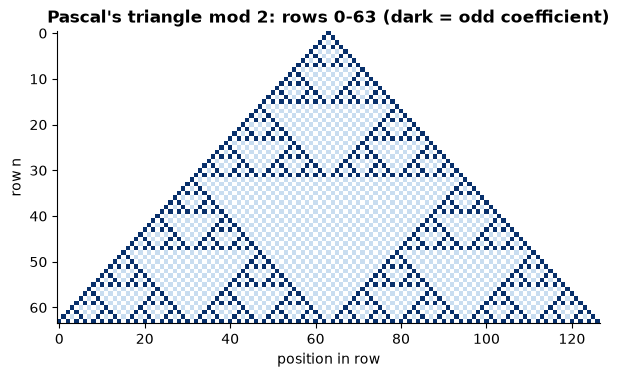

In [4]:
def pascal(n_rows):
    """Rows 0..n_rows-1 of Pascal's triangle using only Pascal's rule (additions)."""
    rows = [[1]]
    for n in range(1, n_rows):
        prev = rows[-1]
        rows.append([1] + [prev[k - 1] + prev[k] for k in range(1, n)] + [1])
    return rows

T = pascal(12)
for row in T[:8]:
    print(" ".join(f"{v:3d}" for v in row).center(60))
assert all(T[n][k] == math.comb(n, k) for n in range(12) for k in range(n + 1))

# Binomial theorem, checked with numbers
x, y, n = 3, 5, 7
print(f"(3 + 5)^7 = {(x + y) ** n} and the binomial sum = {sum(math.comb(n, k) * x**k * y**(n - k) for k in range(n + 1))}")

# Identities, checked over many values
for n in range(0, 30):
    assert sum(math.comb(n, k) for k in range(n + 1)) == 2 ** n
    if n >= 1:
        assert sum((-1) ** k * math.comb(n, k) for k in range(n + 1)) == 0
for m_ in range(8):
    for n_ in range(8):
        for r in range(m_ + n_ + 1):
            assert sum(math.comb(m_, k) * math.comb(n_, r - k) for k in range(r + 1)) == math.comb(m_ + n_, r)
for r in range(6):
    for n in range(r, 25):
        assert sum(math.comb(i, r) for i in range(r, n + 1)) == math.comb(n + 1, r + 1)
print("row sum, alternating sum, Vandermonde and hockey-stick identities all verified")

# A picture: Pascal's triangle modulo 2 (odd entries dark) reveals the Sierpinski triangle
N = 64
grid = np.full((N, 2 * N - 1), np.nan)
row = [1]
for n in range(N):
    for k, v in enumerate(row):
        grid[n, N - 1 - n + 2 * k] = v % 2
    row = [1] + [(row[k - 1] + row[k]) % 2 for k in range(1, len(row))] + [1]   # mod 2 keeps numbers small
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.imshow(grid, cmap="Blues", interpolation="nearest", aspect="auto", vmin=-0.3, vmax=1)
ax.set_title("Pascal's triangle mod 2: rows 0-63 (dark = odd coefficient)")
ax.set_xlabel("position in row"); ax.set_ylabel("row n"); ax.grid(False)
plt.show()

**What just happened?** The triangle built from additions alone equals `math.comb` everywhere, and all five identities held for every value tested. Colouring odd entries reveals the self-similar **Sierpinski triangle**. (Lucas's theorem explains it: $\binom{n}{k}$ is odd exactly when every binary 1-bit of k is also a 1-bit of n.)

**Multinomial theorem.** $(x_1 + \dots + x_m)^n = \sum \binom{n}{k_1, \dots, k_m} x_1^{k_1}\cdots x_m^{k_m}$ over all $k_1 + \dots + k_m = n$, where $\binom{n}{k_1,\dots,k_m} = \frac{n!}{k_1!\cdots k_m!}$. For example the coefficient of $x^2y^3z$ in $(x+y+z)^6$ is $\frac{6!}{2!\,3!\,1!} = 60$: the number of 6-letter words with two x's, three y's and one z.

In [5]:
words = Counter("".join(w) for w in product("xyz", repeat=6))               # expand (x+y+z)^6 term by term
coef = sum(c for w, c in words.items() if Counter(w) == Counter({"x": 2, "y": 3, "z": 1}))
print("coefficient of x^2 y^3 z in (x+y+z)^6 by expansion:", coef, "| formula 6!/(2!3!1!) =",
      math.factorial(6) // (math.factorial(2) * math.factorial(3)))

coefficient of x^2 y^3 z in (x+y+z)^6 by expansion: 60 | formula 6!/(2!3!1!) = 60


---
## 4. The pigeonhole principle and the birthday paradox

> **In plain English:** put more items than boxes and two must share a box; with random placement, sharing happens far sooner than you would guess.

**Pigeonhole principle.** If more than k objects go into k boxes, some box holds at least two. **Generalized:** if N objects go into k boxes, some box holds at least $\lceil N/k \rceil$.

*Proof (contradiction):* if every box held at most $\lceil N/k\rceil - 1 < N/k$ objects, the total would be less than $k \cdot N/k = N$. ∎

It sounds trivial but proves surprising facts:
- Among 367 people, two share a birthday (366 possible birthdays). Among 100 people, at least $\lceil 100/12 \rceil = 9$ share a birth month.
- **Hashing:** a hash function from a big key space into m buckets cannot be injective once there are more than m keys. Collisions are not a bug in the hash function, they are forced (notebook 01, Section 7: no injection from a larger set to a smaller one).
- **Lossless compression cannot shrink every file.** There are $2^n$ files of n bits but only $2^n - 1$ files *shorter* than n bits ($1 + 2 + \dots + 2^{n-1}$), so no lossless compressor can map every n-bit file to a shorter one.

### The birthday paradox
Pigeonhole needs 367 people to *guarantee* a shared birthday. But collisions become *likely* much sooner. With n people and m = 365 equally likely days, the probability that all birthdays are different is
$$P(\text{no match}) = \frac{365}{365}\cdot\frac{364}{365}\cdots\frac{365-n+1}{365} = \prod_{i=0}^{n-1}\Big(1 - \frac{i}{m}\Big) \approx e^{-n(n-1)/(2m)}.$$
The intuition: n people form $\binom{n}{2}$ pairs, and each pair matches with probability 1/m. The 50% point is near $n \approx 1.1774\sqrt{m}$ (from $e^{-n^2/2m} = 1/2$, so $n = \sqrt{2 \ln 2 \cdot m}$).

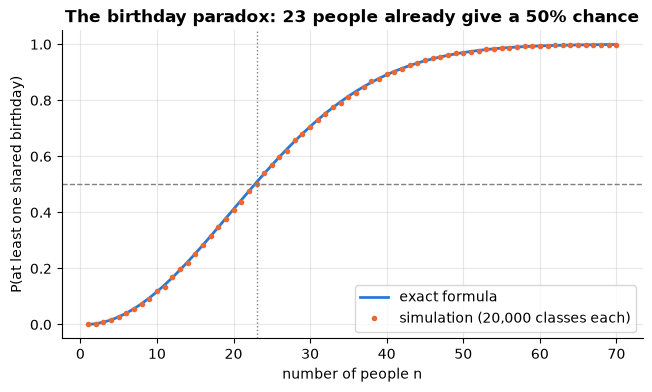

smallest n with P >= 0.5: 23, P = 0.5073; sqrt approximation 1.1774*sqrt(365) = 22.5
P(shared) for n = 50: 0.970; for n = 70: 0.9992


In [6]:
def p_shared(n, m=365):
    """Exact probability that at least two of n people share one of m equally likely days."""
    p_distinct = 1.0
    for i in range(n):
        p_distinct *= (m - i) / m
    return 1 - p_distinct

# Monte Carlo check: 20,000 simulated classes for each class size (vectorised with numpy)
rng = np.random.default_rng(0)
ns = np.arange(1, 71)
sim = []
for n in ns:
    days = rng.integers(0, 365, size=(20_000, n))
    days.sort(axis=1)
    sim.append(np.mean((np.diff(days, axis=1) == 0).any(axis=1)))          # any equal neighbours = a match
exact = [p_shared(n) for n in ns]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(ns, exact, label="exact formula")
ax.plot(ns, sim, "o", ms=3, label="simulation (20,000 classes each)")
ax.axhline(0.5, color="gray", ls="--", lw=1)
n50 = next(n for n in ns if p_shared(n) >= 0.5)
ax.axvline(n50, color="gray", ls=":", lw=1)
ax.set_xlabel("number of people n"); ax.set_ylabel("P(at least one shared birthday)")
ax.set_title("The birthday paradox: 23 people already give a 50% chance"); ax.legend()
plt.show()
print(f"smallest n with P >= 0.5: {n50}, P = {p_shared(n50):.4f}; sqrt approximation 1.1774*sqrt(365) = {1.1774 * 365 ** 0.5:.1f}")
print(f"P(shared) for n = 50: {p_shared(50):.3f}; for n = 70: {p_shared(70):.4f}")
assert max(abs(a - b) for a, b in zip(exact, sim)) < 0.02

**What just happened?** The simulated curve sits on the exact formula. With 23 people the probability of a shared birthday is 0.5073, with 50 people it is 0.970, and with 70 people it is 0.9992, even though pigeonhole only *guarantees* a match at 367.

### Hash collisions arrive at about √m
The same maths says that if you hash random keys into m buckets, the first collision appears after about $\sqrt{\pi m / 2}$ keys on average. For a 32-bit hash (m ≈ 4.3 billion) that is only about 82,000 keys. Let us measure it with a real cryptographic hash (SHA-256 from Python's `hashlib`) cut down to 20 bits, so m = 1,048,576 and the prediction is $\sqrt{\pi \cdot 2^{20} / 2} \approx 1283$.

In [7]:
def keys_until_collision(bits, seed):
    """Hash fresh strings with SHA-256, keep the first `bits` bits, stop at the first repeated value."""
    seen = set()
    i = 0
    while True:
        h = hashlib.sha256(f"key-{seed}-{i}".encode()).digest()
        bucket = int.from_bytes(h[:4], "big") >> (32 - bits)            # first `bits` bits
        if bucket in seen:
            return i + 1                                                  # number of keys inserted
        seen.add(bucket)
        i += 1

bits = 20
trials = [keys_until_collision(bits, seed) for seed in range(300)]
m = 2 ** bits
print(f"m = 2^{bits} = {m:,} buckets")
print(f"mean keys until first collision over 300 runs: {np.mean(trials):.0f}  (theory sqrt(pi*m/2) = {math.sqrt(math.pi * m / 2):.0f})")
print(f"pigeonhole guarantees a collision only by key {m + 1:,}")

m = 2^20 = 1,048,576 buckets
mean keys until first collision over 300 runs: 1279  (theory sqrt(pi*m/2) = 1283)
pigeonhole guarantees a collision only by key 1,048,577


**What just happened?** On average the first collision came after about 1,280 keys, close to the theoretical 1,283 and about 800 times sooner than the pigeonhole guarantee. This is why databases and caches *must* handle collisions ([`dsa/04` hashing](../../00_AI_Fundamentals/dsa/04_hashing.ipynb)), why 32-bit IDs are unsafe for large datasets, and why cryptographic hashes use 256 bits ("birthday attacks" need about $2^{128}$ tries).

> ⚠️ **Common mistake:** thinking you need about m/2 keys for a 50% collision chance. You need only about $1.18\sqrt{m}$: for 365 days that is 23 people, not 183.

---
## 5. Inclusion–exclusion, derangements and surjections

> **In plain English:** to count 'at least one of', add the groups, subtract what you double-counted, add back what you over-subtracted, and so on.

**Principle of inclusion–exclusion (PIE).** For finite sets $A_1, \dots, A_n$:
$$\Big|\bigcup_{i=1}^{n} A_i\Big| = \sum_i |A_i| - \sum_{i<j} |A_i \cap A_j| + \sum_{i<j<k} |A_i \cap A_j \cap A_k| - \dots + (-1)^{n+1}|A_1 \cap \dots \cap A_n|.$$
*Why it works:* an element that lies in exactly t ≥ 1 of the sets is counted $\binom{t}{1} - \binom{t}{2} + \binom{t}{3} - \dots = 1$ time (by the alternating-sum identity of Section 3). ∎

**Worked example.** How many integers from 1 to 1000 are divisible by 2, 3 or 5? $|A_2| = 500$, $|A_3| = 333$, $|A_5| = 200$, $|A_6| = 166$, $|A_{10}| = 100$, $|A_{15}| = 66$, $|A_{30}| = 33$. Total: 500 + 333 + 200 − 166 − 100 − 66 + 33 = **734**.

In [8]:
def inclusion_exclusion(N, divisors_):
    """How many of 1..N are divisible by at least one of `divisors_` (assumed pairwise coprime)."""
    total = 0
    for r in range(1, len(divisors_) + 1):
        for group in combinations(divisors_, r):
            total += (-1) ** (r + 1) * (N // math.prod(group))    # |A_d1 ∩ ... ∩ A_dr| = N // (d1...dr)
    return total

print("PIE:", inclusion_exclusion(1000, [2, 3, 5]),
      "| brute force:", sum(1 for k in range(1, 1001) if k % 2 == 0 or k % 3 == 0 or k % 5 == 0))
for N in [1, 7, 100, 999, 12345]:
    assert inclusion_exclusion(N, [2, 3, 5, 7]) == sum(1 for k in range(1, N + 1) if any(k % d == 0 for d in [2, 3, 5, 7]))

PIE: 734 | brute force: 734


### Derangements (the hat-check problem)
n people check their hats; the hats are handed back at random. What is the chance that **nobody** gets their own hat? A permutation with no fixed point is a **derangement**; let $D_n$ be their number.

Let $A_i$ = permutations that fix person i. Then $|A_{i_1} \cap \dots \cap A_{i_k}| = (n-k)!$, and PIE gives
$$D_n = n! - \binom{n}{1}(n-1)! + \binom{n}{2}(n-2)! - \dots = n!\sum_{k=0}^{n}\frac{(-1)^k}{k!} \;\xrightarrow{\ }\; \frac{n!}{e}.$$
So the probability of a derangement tends to $1/e \approx 0.3679$, almost independent of n. There is also a recurrence: $D_n = (n-1)(D_{n-1} + D_{n-2})$ with $D_0 = 1$, $D_1 = 0$.

In [9]:
def derangements_pie(n):
    return sum((-1) ** k * math.comb(n, k) * math.factorial(n - k) for k in range(n + 1))

@lru_cache(maxsize=None)
def derangements_rec(n):
    if n == 0: return 1
    if n == 1: return 0
    return (n - 1) * (derangements_rec(n - 1) + derangements_rec(n - 2))

def derangements_brute(n):
    return sum(1 for p in permutations(range(n)) if all(p[i] != i for i in range(n)))

rows = []
for n in range(0, 10):
    d = derangements_pie(n)
    assert d == derangements_rec(n)
    if n >= 1:
        assert d == round(math.factorial(n) / math.e)        # D_n is the integer nearest to n!/e
    if n <= 8:
        assert d == derangements_brute(n)
    rows.append({"n": n, "D_n": d, "n!": math.factorial(n), "D_n / n!": round(d / math.factorial(n), 6)})
display(pd.DataFrame(rows).set_index("n"))
print("1/e =", round(1 / math.e, 6))

# Simulation: 100,000 random hat returns for 10 people
perm = np.argsort(rng.random((100_000, 10)), axis=1)                     # random permutations
print("simulated P(nobody gets own hat), n = 10:", np.mean((perm != np.arange(10)).all(axis=1)))

,D_n,n!,D_n / n!
n,,,
0,1,1,1.000000
1,0,1,0.000000
2,1,2,0.500000
3,2,6,0.333333
4,9,24,0.375000
5,44,120,0.366667
6,265,720,0.368056
7,1854,5040,0.367857
8,14833,40320,0.367882


1/e = 0.367879
simulated P(nobody gets own hat), n = 10: 0.36776


**What just happened?** Three independent methods (PIE, the recurrence and brute force over all permutations) agree, and $D_n$ is the nearest integer to $n!/e$ for every n ≥ 1. The fraction $D_n/n!$ settles at 0.367879 by n = 9, and the simulation lands close to it.

### Counting surjections
How many functions from an m-set onto an n-set (every output used)? Let $A_i$ = functions that miss output i. Functions missing a given set of k outputs: $(n-k)^m$. So
$$\#\text{surjections} = \sum_{k=0}^{n} (-1)^k \binom{n}{k} (n-k)^m.$$
Example: m = 5 tasks onto n = 3 workers so that nobody is idle: $3^5 - 3\cdot 2^5 + 3 \cdot 1^5 - 0 = 243 - 96 + 3 = 150$.

In [10]:
def surjections(m, n):
    return sum((-1) ** k * math.comb(n, k) * (n - k) ** m for k in range(n + 1))

def surjections_brute(m, n):
    return sum(1 for f in product(range(n), repeat=m) if len(set(f)) == n)

print("onto functions 5 -> 3:", surjections(5, 3))
for m_ in range(0, 7):
    for n_ in range(0, 5):
        assert surjections(m_, n_) == surjections_brute(m_, n_)
print("formula matches brute force for all m <= 6, n <= 4")

onto functions 5 -> 3: 150
formula matches brute force for all m <= 6, n <= 4


---
## 6. Modelling with recurrence relations

> **In plain English:** a recurrence describes each value using earlier values, which is often the easiest way to model a counting problem.

**Definition.** A **recurrence relation** for a sequence $a_0, a_1, \dots$ expresses $a_n$ in terms of earlier terms. Together with enough **initial conditions** it determines the sequence uniquely (by strong induction).

Three classic models:

| Problem | Recurrence | Initial values | Reasoning |
|---|---|---|---|
| **Tower of Hanoi**: moves to shift n discs | $H_n = 2H_{n-1} + 1$ | $H_1 = 1$ | move n − 1 discs away, move the biggest, move n − 1 back on top |
| **Bit strings of length n with no two consecutive 1s** | $a_n = a_{n-1} + a_{n-2}$ | $a_1 = 2$, $a_2 = 3$ | the string ends in 0 (anything valid before it) or in 01 |
| **Compound interest**: balance after n years at rate r | $B_n = (1 + r)B_{n-1}$ | $B_0$ = deposit | each year multiplies by 1 + r |

The second one is the **Fibonacci** recurrence $F_n = F_{n-1} + F_{n-2}$ ($F_0 = 0, F_1 = 1$) shifted: $a_n = F_{n+2}$.

In [11]:
def hanoi(n, src="A", dst="C", via="B", moves=None):
    """Generate the actual moves; their number satisfies H_n = 2 H_{n-1} + 1."""
    if moves is None:
        moves = []
    if n == 0:
        return moves
    hanoi(n - 1, src, via, dst, moves)
    moves.append((n, src, dst))
    hanoi(n - 1, via, dst, src, moves)
    return moves

print("Hanoi with 3 discs:", hanoi(3))
for n in range(1, 16):
    assert len(hanoi(n)) == 2 ** n - 1                    # the closed form, proved in Section 7.3

def no_two_ones(n):
    return sum(1 for s in product("01", repeat=n) if "11" not in "".join(s))

fib = [0, 1]
while len(fib) < 30:
    fib.append(fib[-1] + fib[-2])
print("strings with no '11', n = 1..10:", [no_two_ones(n) for n in range(1, 11)])
assert all(no_two_ones(n) == fib[n + 2] for n in range(1, 18))
print("matches Fibonacci F(n+2) for n = 1..17")

Hanoi with 3 discs: [(1, 'A', 'C'), (2, 'A', 'B'), (1, 'C', 'B'), (3, 'A', 'C'), (1, 'B', 'A'), (2, 'B', 'C'), (1, 'A', 'C')]


strings with no '11', n = 1..10: [2, 3, 5, 8, 13, 21, 34, 55, 89, 144]


matches Fibonacci F(n+2) for n = 1..17


---
## 7. Solving linear recurrences

> **In plain English:** turn a step-by-step recurrence into a direct formula you can evaluate for any n.

A **linear homogeneous recurrence with constant coefficients** of degree k is
$$a_n = c_1 a_{n-1} + c_2 a_{n-2} + \dots + c_k a_{n-k}.$$

**Characteristic-root method.** Try $a_n = r^n$. Dividing by $r^{n-k}$ gives the **characteristic equation**
$$r^k - c_1 r^{k-1} - \dots - c_k = 0.$$
- If its roots $r_1, \dots, r_k$ are **distinct**, every solution is $a_n = \alpha_1 r_1^n + \dots + \alpha_k r_k^n$.
- If a root r has **multiplicity m**, it contributes $(\alpha_0 + \alpha_1 n + \dots + \alpha_{m-1} n^{m-1})\, r^n$.
- The constants $\alpha_i$ come from the initial conditions (a small linear system).

### 7.1 Fibonacci by hand (Binet's formula)
$r^2 - r - 1 = 0$ gives $\varphi = \frac{1+\sqrt5}{2} \approx 1.618$ and $\psi = \frac{1-\sqrt5}{2} \approx -0.618$. So $F_n = \alpha\varphi^n + \beta\psi^n$. From $F_0 = 0$: $\beta = -\alpha$. From $F_1 = 1$: $\alpha(\varphi - \psi) = 1$, so $\alpha = 1/\sqrt5$:
$$F_n = \frac{\varphi^n - \psi^n}{\sqrt5}.$$
Since $|\psi| < 1$, $F_n$ is the integer nearest to $\varphi^n/\sqrt5$: Fibonacci numbers grow like $1.618^n$, which is why naive recursive Fibonacci takes exponential time.

### 7.2 A repeated root by hand
$a_n = 6a_{n-1} - 9a_{n-2}$, $a_0 = 1$, $a_1 = 6$. Characteristic equation $r^2 - 6r + 9 = (r-3)^2 = 0$: root 3 twice. So $a_n = (\alpha + \beta n)3^n$. $a_0 = 1 \Rightarrow \alpha = 1$; $a_1 = (1 + \beta)\cdot 3 = 6 \Rightarrow \beta = 1$. Answer: $a_n = (1 + n)\,3^n$.

Now a general solver: find the roots with `numpy.roots`, group repeated roots, solve for the constants, and compare with direct iteration.

In [12]:
def iterate(coeffs, init, N):
    """a_n = c1 a_{n-1} + ... + ck a_{n-k}, computed directly (exact integers)."""
    a = list(init)
    while len(a) < N:
        a.append(sum(c * a[-i - 1] for i, c in enumerate(coeffs)))
    return a[:N]

def solve_linear_recurrence(coeffs, init, tol=1e-6):
    """Closed form via characteristic roots. Returns (roots with multiplicities, formula function)."""
    k = len(coeffs)
    roots = np.roots([1] + [-c for c in coeffs])                 # r^k - c1 r^{k-1} - ... - ck
    groups = []                                                  # [(root, multiplicity)]
    for r in roots:
        for g in groups:
            if abs(g[0] - r) < tol:
                g[1] += 1
                break
        else:
            groups.append([r, 1])
    basis = [(r, j) for r, m in groups for j in range(m)]         # basis functions n^j r^n
    # Solve sum_b alpha_b * n^j r^n = init[n] for n = 0..k-1
    A = np.array([[(n ** j) * (r ** n) for (r, j) in basis] for n in range(k)], dtype=complex)
    alpha = np.linalg.solve(A, np.array(init, dtype=complex))
    def formula(n):
        return sum(a_ * (n ** j) * (r ** n) for a_, (r, j) in zip(alpha, basis)).real
    return [(complex(np.round(r, 6)), m) for r, m in groups], formula

tests = {
    "Fibonacci  a_n = a_{n-1} + a_{n-2}":            ([1, 1], [0, 1]),
    "repeated root  a_n = 6a_{n-1} - 9a_{n-2}":     ([6, -9], [1, 6]),
    "a_n = 5a_{n-1} - 6a_{n-2}":                    ([5, -6], [2, 5]),
    "complex roots  a_n = -a_{n-2} (period 4)":     ([0, -1], [1, 0]),
    "degree 3  a_n = 2a_{n-1} + a_{n-2} - 2a_{n-3}": ([2, 1, -2], [3, 2, 6]),
}
for name, (c, init) in tests.items():
    roots, f = solve_linear_recurrence(c, init)
    seq = iterate(c, init, 25)
    err = max(abs(f(n) - seq[n]) / max(1, abs(seq[n])) for n in range(25))
    roots = [(complex(r.real + 0.0, r.imag + 0.0), m) for r, m in roots]       # + 0.0 turns -0 into 0
    shown = ", ".join((f"{r.real:g}" if abs(r.imag) < 1e-9 else f"{r.real:g}{r.imag:+g}i") + (f" (×{m})" if m > 1 else "")
                      for r, m in roots)
    print(f"{name:48s} roots: {shown}")
    print(f"{'':48s} first terms {seq[:8]}, max relative error of closed form over n<25: {err:.1e}")
    assert err < 1e-9

assert all(iterate([6, -9], [1, 6], 30)[n] == (1 + n) * 3 ** n for n in range(30))
phi = (1 + 5 ** 0.5) / 2
assert all(round(phi ** n / 5 ** 0.5) == fib[n] for n in range(30))
print("hand-derived formulas (1+n)3^n and round(phi^n / sqrt 5) confirmed")

Fibonacci  a_n = a_{n-1} + a_{n-2}               roots: 1.61803, -0.618034
                                                 first terms [0, 1, 1, 2, 3, 5, 8, 13], max relative error of closed form over n<25: 6.3e-16
repeated root  a_n = 6a_{n-1} - 9a_{n-2}         roots: 3 (×2)
                                                 first terms [1, 6, 27, 108, 405, 1458, 5103, 17496], max relative error of closed form over n<25: 3.7e-14
a_n = 5a_{n-1} - 6a_{n-2}                        roots: 3, 2
                                                 first terms [2, 5, 13, 35, 97, 275, 793, 2315], max relative error of closed form over n<25: 3.1e-15
complex roots  a_n = -a_{n-2} (period 4)         roots: 0+1i, 0-1i
                                                 first terms [1, 0, -1, 0, 1, 0, -1, 0], max relative error of closed form over n<25: 0.0e+00
degree 3  a_n = 2a_{n-1} + a_{n-2} - 2a_{n-3}    roots: -1, 2, 1
                                                 first terms [3, 2, 6, 8, 18, 32,

**What just happened?** For every recurrence, the closed form built from the characteristic roots reproduced 25 terms of the sequence with a relative error around $10^{-15}$ or smaller (floating-point round-off only). The cases cover distinct real roots, a repeated root (3 twice), complex roots (±i, which make the sequence 1, 0, −1, 0, 1, … periodic) and a cubic. The hand-derived answers to 7.1 and 7.2 are confirmed with exact integers.

> ⚠️ **Common mistake:** for a repeated root, writing $\alpha 3^n + \beta 3^n$. That is really one constant, so you cannot match two initial conditions. The second basis function must be $n\,3^n$.

### 7.3 Non-homogeneous recurrences
For $a_n = c_1 a_{n-1} + \dots + F(n)$, the solution is (general homogeneous solution) + (one particular solution). Tower of Hanoi: $H_n = 2H_{n-1} + 1$. Homogeneous part: $\alpha 2^n$. Try a constant particular solution $p$: $p = 2p + 1$, so $p = -1$. Then $H_n = \alpha 2^n - 1$, and $H_1 = 1$ gives $\alpha = 1$: $H_n = 2^n - 1$, as the code in Section 6 confirmed. (64 discs take $2^{64} - 1 \approx 1.8 \times 10^{19}$ moves.)

### 7.4 Fast Fibonacci: matrix powers in O(log n)
The recurrence is linear, so one step is a matrix multiplication: $\begin{pmatrix}F_{n+1}\\F_n\end{pmatrix} = \begin{pmatrix}1&1\\1&0\end{pmatrix}\begin{pmatrix}F_n\\F_{n-1}\end{pmatrix}$, hence $\begin{pmatrix}1&1\\1&0\end{pmatrix}^n = \begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}$. **Repeated squaring** computes the n-th power with O(log n) matrix multiplications, and works with exact integers (Binet's formula with floats breaks down after about $F_{70}$).

In [13]:
def mat_mult(X, Y):
    return [[X[0][0] * Y[0][0] + X[0][1] * Y[1][0], X[0][0] * Y[0][1] + X[0][1] * Y[1][1]],
            [X[1][0] * Y[0][0] + X[1][1] * Y[1][0], X[1][0] * Y[0][1] + X[1][1] * Y[1][1]]]

def fib_matrix(n):
    """F_n via repeated squaring of [[1,1],[1,0]]: O(log n) multiplications."""
    result, base = [[1, 0], [0, 1]], [[1, 1], [1, 0]]
    while n:
        if n & 1:
            result = mat_mult(result, base)
        base = mat_mult(base, base)
        n >>= 1
    return result[0][1]

def fib_iter(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

assert all(fib_matrix(n) == fib_iter(n) for n in range(300))
binet_fails = next(n for n in range(200) if round(phi ** n / 5 ** 0.5) != fib_iter(n))
print("Binet with 64-bit floats first goes wrong at n =", binet_fails)
for n in [10_000, 100_000]:
    t0 = time.perf_counter(); a = fib_iter(n); t1 = time.perf_counter(); b = fib_matrix(n); t2 = time.perf_counter()
    assert a == b
    print(f"F({n:,}) has about {int(a.bit_length() * math.log10(2)):,} digits; iterative {1000 * (t1 - t0):7.1f} ms, matrix power {1000 * (t2 - t1):6.1f} ms")

Binet with 64-bit floats first goes wrong at n = 71
F(10,000) has about 2,089 digits; iterative    17.8 ms, matrix power   10.9 ms


F(100,000) has about 20,898 digits; iterative  1236.1 ms, matrix power  153.6 ms


**What just happened?** The matrix method agrees with simple iteration, is much faster for large n, and stays exact. Binet's formula with floating point fails from n = 71 on, because $\varphi^n$ then needs more than the 53 significant bits a 64-bit float holds. (For very large n the cost is dominated by multiplying huge integers, so "O(log n)" counts multiplications, not bit operations.)

### 7.5 Linear vs divide-and-conquer recurrences

| Recurrence type | Example | Solution method | Answer |
|---|---|---|---|
| Linear, constant coefficients | $F_n = F_{n-1} + F_{n-2}$ | characteristic roots | $\Theta(\varphi^n)$ |
| Subtract-and-conquer | $T(n) = T(n-1) + n$ (insertion sort worst case) | unroll / sum | $\Theta(n^2)$ |
| Divide-and-conquer | $T(n) = 2T(n/2) + n$ (merge sort) | **Master theorem**, recursion tree ([`dsa/01`](../../00_AI_Fundamentals/dsa/01_complexity_analysis_and_recursion.ipynb)) | $\Theta(n \log n)$ |
| Divide-and-conquer | $T(n) = 3T(n/2) + n$ (Karatsuba, [`dsa/08`](../../00_AI_Fundamentals/dsa/08_greedy_and_divide_and_conquer.ipynb)) | Master theorem, case 1 | $\Theta(n^{\log_2 3}) \approx \Theta(n^{1.585})$ |

🎓 **Exam / interview tip:** "naive recursive Fibonacci is exponential" has an exact answer. The number of calls $C_n = C_{n-1} + C_{n-2} + 1$ solves to $C_n = 2F_{n+1} - 1 = \Theta(\varphi^n)$. Memoization (DP) brings it to Θ(n), and matrix powers to Θ(log n) multiplications.

---
## 8. Generating functions

> **In plain English:** store a whole sequence as the coefficients of a polynomial; multiplying polynomials then does the counting for you.

**Idea.** Store a whole sequence $a_0, a_1, a_2, \dots$ as the coefficients of one power series, its **ordinary generating function (OGF)**:
$$G(x) = a_0 + a_1 x + a_2 x^2 + \dots = \sum_{n \ge 0} a_n x^n.$$
x is just a placeholder: we never plug in a number, we only manipulate coefficients. The key fact: **multiplying generating functions convolves their coefficients**, and convolution is exactly the product rule summed over all ways to split a total. If $A(x)$ counts ways to make total i with one kind of choice and $B(x)$ with another, then the coefficient of $x^n$ in $A(x)B(x)$ counts ways to make n with both.

**Example 1 (dice).** One die is $x + x^2 + \dots + x^6$ (one way to roll each value). Two dice: $(x + \dots + x^6)^2$; the coefficient of $x^7$ is 6, so $P(\text{sum} = 7) = 6/36$.

**Example 2 (coin change).** Ways to pay n cents with coins 1, 5, 10, 25 (any number of each): the 5-cent coin contributes $1 + x^5 + x^{10} + \dots = \frac{1}{1 - x^5}$ (use it 0, 1, 2, … times), so
$$G(x) = \frac{1}{(1-x)(1-x^5)(1-x^{10})(1-x^{25})}.$$
The coefficient of $x^{100}$ is the answer.

In [14]:
def poly_mul(p, q, max_deg=None):
    """Multiply two polynomials given as coefficient lists (index = power). O(len(p) * len(q))."""
    out = [0] * (len(p) + len(q) - 1)
    for i, a in enumerate(p):
        if a:
            for j, b in enumerate(q):
                out[i + j] += a * b                     # x^i * x^j = x^(i+j): convolution
    return out[: max_deg + 1] if max_deg is not None else out

# Example 1: two dice
die = [0, 1, 1, 1, 1, 1, 1]                             # x + x^2 + ... + x^6
two = poly_mul(die, die)
print("ways to roll each sum with two dice:", {s: c for s, c in enumerate(two) if c})
assert two == list(np.convolve(die, die))                # numpy's convolve does the same thing

# Example 2: coin change via generating functions
N = 100
G = [1] + [0] * N                                       # the polynomial "1"
for coin in [1, 5, 10, 25]:
    factor = [1 if i % coin == 0 else 0 for i in range(N + 1)]   # 1 + x^coin + x^{2 coin} + ... (truncated)
    G = poly_mul(G, factor, max_deg=N)
print("ways to make 100 cents from 1, 5, 10, 25:", G[100])

# Cross-check with the classic DP (dsa/09)
ways = [1] + [0] * N
for coin in [1, 5, 10, 25]:
    for amount in range(coin, N + 1):
        ways[amount] += ways[amount - coin]
assert ways == G
print("dynamic programming agrees:", ways[100])

ways to roll each sum with two dice: {2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 8: 5, 9: 4, 10: 3, 11: 2, 12: 1}
ways to make 100 cents from 1, 5, 10, 25: 242
dynamic programming agrees: 242


**What just happened?** Multiplying polynomials counted all 242 ways to make a dollar, and the DP from [`dsa/09`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb) is literally the same computation done one coin at a time. Two dice give the familiar triangle 1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1.

**Speed.** Multiplying two polynomials of degree n the schoolbook way is O(n²). The **Fast Fourier Transform** does it in O(n log n), which is how big convolutions are computed in practice ([`advanced_algorithms/07`](../../00_AI_Fundamentals/advanced_algorithms/07_computational_geometry_and_fft.ipynb) implements it).

### From a recurrence to a generating function and back
Let $F(x) = \sum F_n x^n$ for Fibonacci. Multiply the recurrence $F_n = F_{n-1} + F_{n-2}$ by $x^n$ and sum over n ≥ 2:
$$F(x) - F_0 - F_1 x = x\,(F(x) - F_0) + x^2 F(x) \;\Rightarrow\; F(x) = \frac{x}{1 - x - x^2}.$$
A whole infinite sequence is packed into one fraction. Expanding it as a power series (long division of polynomials) unpacks the sequence again, and partial fractions on $\frac{x}{1-x-x^2}$ give back Binet's formula.

In [15]:
def series_divide(num, den, n_terms):
    """Power-series coefficients of num(x) / den(x), assuming den[0] != 0 (long division)."""
    num = num + [0] * n_terms
    out = []
    for n in range(n_terms):
        c = (num[n] - sum(den[k] * out[n - k] for k in range(1, min(n, len(den) - 1) + 1))) / den[0]
        out.append(c)
    return out

coeffs = series_divide([0, 1], [1, -1, -1], 15)        # x / (1 - x - x^2)
print("x / (1 - x - x^2) =", " + ".join(f"{int(c)}x^{n}" for n, c in enumerate(coeffs[:10]) if c), "+ ...")
assert [int(c) for c in coeffs] == fib[:15]

x / (1 - x - x^2) = 1x^1 + 1x^2 + 2x^3 + 3x^4 + 5x^5 + 8x^6 + 13x^7 + 21x^8 + 34x^9 + ...


---
## 9. Catalan and Stirling numbers

> **In plain English:** two famous number families that count trees, bracketings and ways to split a group.

### 9.1 Catalan numbers
$$C_n = \frac{1}{n+1}\binom{2n}{n} \quad\text{with}\quad C_0 = 1,\ C_{n+1} = \sum_{i=0}^{n} C_i\,C_{n-i}.$$
Sequence: 1, 1, 2, 5, 14, 42, 132, 429, 1430, 4862, 16796, …

The recurrence comes from splitting at the "first" structure. Catalan numbers count, among many other things:
- **balanced strings** of n pairs of parentheses (`(())`, `()()` for n = 2);
- **binary tree shapes** with n nodes (choose i nodes for the left subtree and n − 1 − i for the right);
- ways to fully **parenthesize a product** of n + 1 factors (matrix-chain multiplication orders, [`dsa/09`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb));
- **parse trees** of a sentence of n + 1 words under a binary grammar;
- triangulations of a convex polygon with n + 2 sides.

We count the first three by brute force and compare.

In [16]:
def catalan(n):
    return math.comb(2 * n, n) // (n + 1)

def balanced(n):
    """Count balanced strings among all 2^(2n) strings of '(' and ')'."""
    count = 0
    for s in product("()", repeat=2 * n):
        depth = 0
        for ch in s:
            depth += 1 if ch == "(" else -1
            if depth < 0:
                break
        else:
            count += depth == 0
    return count

@lru_cache(maxsize=None)
def tree_shapes(n):
    """Binary trees with n nodes: root + i nodes on the left + n-1-i on the right."""
    if n == 0:
        return 1
    return sum(tree_shapes(i) * tree_shapes(n - 1 - i) for i in range(n))

def bracketings(factors):
    """All full parenthesizations of a product, as strings, e.g. ['((ab)c)', '(a(bc))']."""
    if len(factors) == 1:
        return [factors]
    out = []
    for split in range(1, len(factors)):
        for left in bracketings(factors[:split]):
            for right in bracketings(factors[split:]):
                out.append(f"({left}{right})")
    return out

print("bracketings of abcd:", bracketings("abcd"))
rows = []
for n in range(0, 9):
    rows.append({"n": n, "C(2n,n)/(n+1)": catalan(n), "balanced strings": balanced(n),
                 "binary tree shapes": tree_shapes(n), "bracketings of n+1 factors": len(bracketings("abcdefghij"[: n + 1]))})
df = pd.DataFrame(rows).set_index("n")
display(df)
assert (df.nunique(axis=1) == 1).all()

bracketings of abcd: ['(a(b(cd)))', '(a((bc)d))', '((ab)(cd))', '((a(bc))d)', '(((ab)c)d)']


,"C(2n,n)/(n+1)",balanced strings,binary tree shapes,bracketings of n+1 factors
n,,,,
0,1,1,1,1
1,1,1,1,1
2,2,2,2,2
3,5,5,5,5
4,14,14,14,14
5,42,42,42,42
6,132,132,132,132
7,429,429,429,429
8,1430,1430,1430,1430


**What just happened?** Four very different objects are counted by the same numbers, and brute force confirms all of them up to n = 8 (65,536 strings of parentheses for n = 8). Matching counts like this usually mean there is a **bijection** between the objects: for example, write a binary tree in preorder with "(" for going left and ")" for coming back.

### 9.2 Stirling numbers of the second kind and Bell numbers
$S(n, k)$ = the number of ways to **partition** an n-element set into exactly k non-empty blocks (unlabelled). Recurrence (look at element n): either it is alone in a new block, $S(n-1, k-1)$ ways, or it joins one of the k blocks of a partition of the other n − 1 elements, $k\,S(n-1, k)$ ways:
$$S(n, k) = k\,S(n-1, k) + S(n-1, k-1), \qquad S(0, 0) = 1.$$
Links to earlier results: a **surjection** from an n-set onto a k-set is a partition into k blocks plus a labelling of the blocks, so surjections = $k!\,S(n, k)$ (Section 5). The **Bell number** $B_n = \sum_k S(n, k)$ counts all partitions, which is the number of **equivalence relations** on an n-set (notebook 01, Section 4).

### 9.3 Stirling numbers of the first kind
The unsigned $c(n, k)$ counts permutations of n elements with exactly k **cycles**. Recurrence: $c(n, k) = (n-1)\,c(n-1, k) + c(n-1, k-1)$ (element n either starts its own cycle or is inserted after one of the n − 1 others). Row sums give $n!$.

In [17]:
@lru_cache(maxsize=None)
def stirling2(n, k):
    if n == k == 0: return 1
    if n == 0 or k == 0: return 0
    return k * stirling2(n - 1, k) + stirling2(n - 1, k - 1)

@lru_cache(maxsize=None)
def stirling1(n, k):
    if n == k == 0: return 1
    if n == 0 or k == 0: return 0
    return (n - 1) * stirling1(n - 1, k) + stirling1(n - 1, k - 1)

def set_partitions(items):
    """Generate every partition of a list into non-empty blocks (brute force)."""
    if not items:
        yield []
        return
    first, rest = items[0], items[1:]
    for p in set_partitions(rest):
        yield [[first]] + p                                     # first in a block of its own
        for i in range(len(p)):                                 # or first joins block i
            yield p[:i] + [[first] + p[i]] + p[i + 1:]

def count_cycles(perm):
    seen, cycles = set(), 0
    for i in range(len(perm)):
        if i not in seen:
            cycles += 1
            while i not in seen:
                seen.add(i); i = perm[i]
    return cycles

print("partitions of {a,b,c}:", list(set_partitions(["a", "b", "c"])))
for n in range(0, 8):
    by_k = Counter(len(p) for p in set_partitions(list(range(n))))
    assert all(by_k.get(k, 0) == stirling2(n, k) for k in range(n + 1))
    assert all(surjections(n, k) == math.factorial(k) * stirling2(n, k) for k in range(n + 1))
    cyc = Counter(count_cycles(p) for p in permutations(range(n)))
    assert all(cyc.get(k, 0) == stirling1(n, k) for k in range(n + 1))

table = pd.DataFrame([[stirling2(n, k) for k in range(0, 8)] for n in range(0, 8)],
                     index=pd.Index(range(8), name="n"), columns=[f"k={k}" for k in range(8)])
table["Bell B_n"] = [sum(stirling2(n, k) for k in range(n + 1)) for n in range(8)]
print("Stirling numbers of the second kind S(n, k) and Bell numbers:")
display(table)
print("c(4, k) for k = 1..4 (permutations of 4 by number of cycles):", [stirling1(4, k) for k in range(1, 5)],
      "sum =", sum(stirling1(4, k) for k in range(1, 5)))

partitions of {a,b,c}: [[['a'], ['b'], ['c']], [['a', 'b'], ['c']], [['b'], ['a', 'c']], [['a'], ['b', 'c']], [['a', 'b', 'c']]]
Stirling numbers of the second kind S(n, k) and Bell numbers:


,k=0,k=1,k=2,k=3,k=4,k=5,k=6,k=7,Bell B_n
n,,,,,,,,,
0,1,0,0,0,0,0,0,0,1
1,0,1,0,0,0,0,0,0,1
2,0,1,1,0,0,0,0,0,2
3,0,1,3,1,0,0,0,0,5
4,0,1,7,6,1,0,0,0,15
5,0,1,15,25,10,1,0,0,52
6,0,1,31,90,65,15,1,0,203
7,0,1,63,301,350,140,21,1,877


c(4, k) for k = 1..4 (permutations of 4 by number of cycles): [6, 11, 6, 1] sum = 24


**What just happened?** Brute-force enumeration of every set partition and every permutation (up to 7 elements) matched both recurrences, and the surjection identity $k!\,S(n,k)$ held. The Bell numbers 1, 1, 2, 5, 15, 52, 203, 877 continue the 1, 2, 5, 15 that notebook 01 found by testing all 65,536 relations on 4 elements. Of the 24 permutations of 4 elements, 6 are a single 4-cycle, 11 have two cycles, 6 have three, and 1 (the identity) has four.

**Complexity.** The recurrences fill an n × k table in O(nk) time with memoization; brute force is hopeless beyond tiny n because $B_n$ grows faster than any exponential $c^n$.

---
## 10. Summary of formulas

> **In plain English:** every formula from this notebook on one page.

| Quantity | Formula | Typical question |
|---|---|---|
| Sequences of length r from n symbols | $n^r$ | PINs, passwords, grid search |
| r-permutations | $n!/(n-r)!$ | podium, ordered selections |
| r-combinations | $\binom{n}{r}$ | committees, subsets of features |
| Combinations with repetition | $\binom{n+r-1}{r}$ | stars and bars, distributing identical items |
| Multiset permutations | $n!/(n_1!\cdots n_k!)$ | arrangements of a word |
| Pigeonhole | some box has ≥ $\lceil N/k\rceil$ | forced collisions |
| Birthday bound | 50% collision at $\approx 1.18\sqrt{m}$ | hash and ID sizes |
| Inclusion–exclusion | alternating sum over intersections | "at least one of" counts |
| Derangements | $D_n = n!\sum (-1)^k/k! \approx n!/e$ | nobody gets their own item |
| Surjections | $\sum_k (-1)^k\binom{n}{k}(n-k)^m = n!\,S(m,n)$ | onto functions |
| Linear recurrence | $\sum \alpha_i n^j r_i^n$ from characteristic roots | closed forms |
| Catalan | $\binom{2n}{n}/(n+1)$ | trees, brackets, parse trees |
| Stirling 2nd kind / Bell | $S(n,k) = kS(n-1,k) + S(n-1,k-1)$ | set partitions, clusterings |

---
## 11. 🔗 How this connects to modern AI: combinatorial explosion

> **In plain English:** counting shows why trying every option is impossible in most AI problems, so we need smarter methods.

Counting tells you **before running anything** whether brute force is feasible.

| AI task | What gets counted | Size |
|---|---|---|
| **Grid search** over hyperparameters | product rule: values per hyperparameter multiplied | 5 hyperparameters with 4, 5, 3, 6, 10 values = 3,600 training runs. Random search and Bayesian optimisation sample this space instead ([`03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb`](../../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb)) |
| **Brute-force feature selection** | non-empty subsets of d features: $2^d - 1$ | d = 30 gives over a billion models; d = 100 gives about $1.3 \times 10^{30}$. Hence greedy forward/backward selection, L1 regularisation ([`03_Machine_Learning/05_feature_engineering/01_feature_engineering.ipynb`](../../03_Machine_Learning/05_feature_engineering/01_feature_engineering.ipynb)) |
| **Decision trees** | trees of depth ≤ k over d binary features: $T_k = 2 + d\,T_{k-1}^2$ (a leaf with one of 2 labels, or a split with two subtrees) | d = 10, depth 3: over 3 billion trees; finding the optimal tree is NP-hard, so CART grows trees greedily ([`03_Machine_Learning/01_supervised/03_decision_trees.ipynb`](../../03_Machine_Learning/01_supervised/03_decision_trees.ipynb)) |
| **Boolean functions** a classifier could represent on n binary inputs | $2^{2^n}$ | n = 5: about 4.3 billion; n = 10: a number with 309 digits. Learning needs inductive bias, not enumeration |
| **Game-tree search** | $b^d$ positions for branching factor b and depth d | chess: Shannon estimated about $10^{120}$ games, so programs prune (alpha-beta) and use learned evaluation ([`classical_ai/02`](../../00_AI_Fundamentals/classical_ai/02_uninformed_search.ipynb)) |
| **LLM decoding** | sequences of length L over a vocabulary of size V: $V^L$ | V = 50,000, L = 20: about $10^{94}$ sequences, more than the roughly $10^{80}$ atoms in the observable universe. Hence greedy, beam search and sampling ([`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb)) |
| **Clustering** | ways to split n points into k clusters: $S(n, k)$ | S(100, 5) ≈ $6.6 \times 10^{67}$, which is why k-means is a local search, not an exhaustive one |
| **Parsing** | binary parse trees of an n-word sentence: $C_{n-1}$ | a 20-word sentence has 1,767,263,190 bracketings; the CYK algorithm uses DP to avoid listing them |

decision trees over 10 binary features, depth <= 0..3: ['2', '42', '17,642', '3,112,401,642']
grid search 4*5*3*6*10 = 3,600 runs
feature subsets: d=30 -> 1,073,741,823; d=100 -> 1.27e+30
Boolean functions of 5 inputs: 4,294,967,296; of 10 inputs: 309 digits
LLM sequences V=50,000, L=20: about 10^94
S(100, 5) = 6.57e+67; Catalan C_19 (20-word sentence) = 1,767,263,190


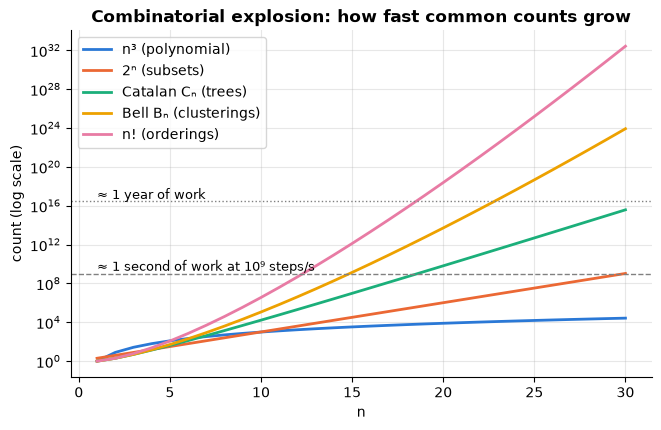

In [18]:
d = 10
T = [2]                                                    # depth 0: a single leaf, labelled 0 or 1
for k in range(1, 4):
    T.append(2 + d * T[-1] ** 2)
print("decision trees over 10 binary features, depth <= 0..3:", [f"{t:,}" for t in T])
print(f"grid search 4*5*3*6*10 = {4 * 5 * 3 * 6 * 10:,} runs")
print(f"feature subsets: d=30 -> {2**30 - 1:,}; d=100 -> {2**100 - 1:.2e}")
print(f"Boolean functions of 5 inputs: {2 ** 2 ** 5:,}; of 10 inputs: {len(str(2 ** 2 ** 10))} digits")
print(f"LLM sequences V=50,000, L=20: about 10^{20 * math.log10(50_000):.0f}")
print(f"S(100, 5) = {float(stirling2(100, 5)):.2e}; Catalan C_19 (20-word sentence) = {catalan(19):,}")

ns_ = np.arange(1, 31)
curves = {
    "n³ (polynomial)": ns_.astype(float) ** 3,
    "2ⁿ (subsets)": 2.0 ** ns_,
    "Catalan Cₙ (trees)": np.array([catalan(int(n)) for n in ns_], dtype=float),
    "Bell Bₙ (clusterings)": np.array([sum(stirling2(int(n), k) for k in range(int(n) + 1)) for n in ns_], dtype=float),
    "n! (orderings)": np.array([math.factorial(int(n)) for n in ns_], dtype=float),
}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, vals in curves.items():
    ax.semilogy(ns_, vals, label=name)
ax.axhline(1e9, color="gray", ls="--", lw=1); ax.text(1, 2e9, "≈ 1 second of work at 10⁹ steps/s", fontsize=9)
ax.axhline(3.15e16, color="gray", ls=":", lw=1)            # 10^9 steps/s × 3.15×10^7 s
ax.text(1, 5e16, "≈ 1 year of work", fontsize=9)
ax.set_xlabel("n"); ax.set_ylabel("count (log scale)")
ax.set_title("Combinatorial explosion: how fast common counts grow"); ax.legend()
plt.show()

**What just happened?** On a log scale a polynomial ($n^3$) bends over while the combinatorial counts shoot up. By n = 30 there are about $10^9$ subsets, about $10^{15}$ binary tree shapes, nearly $10^{24}$ ways to cluster 30 points, and $30! \approx 2.7 \times 10^{32}$ orderings. Anything above the dashed "one second" line is out of reach for an exhaustive search inside a training loop, and above the dotted "one year" line out of reach, period. This is the main reason AI relies on **heuristics, greedy algorithms, dynamic programming, sampling and learning** rather than enumeration.

---
## 12. Recap

> **In plain English:** the key facts to remember, then practice.

- **Sum rule** for "or" (disjoint), **product rule** for "and then", **subtraction rule** for overlaps, **division rule** when each outcome is counted d times.
- Choose r from n: ask *does order matter?* and *is repetition allowed?* The answers pick $n!/(n-r)!$, $\binom{n}{r}$, $n^r$ or $\binom{n+r-1}{r}$ (stars and bars). Multisets: $n!/(n_1!\cdots n_k!)$.
- **Binomial theorem**: $(x+y)^n = \sum\binom{n}{k}x^ky^{n-k}$; **Pascal's rule** $\binom{n}{k} = \binom{n-1}{k-1} + \binom{n-1}{k}$; row sums $2^n$; Vandermonde and hockey stick.
- **Pigeonhole**: N objects in k boxes give a box with ≥ ⌈N/k⌉. Collisions become likely far earlier, at about $1.18\sqrt{m}$ (**birthday paradox**: 23 people; a 20-bit hash collides after about 1,280 keys).
- **Inclusion–exclusion** counts unions by alternating sums; it gives **derangements** ($\approx n!/e$) and **surjections**.
- **Linear recurrences** are solved by the **characteristic equation**: distinct roots give $\sum\alpha_i r_i^n$, a root of multiplicity m contributes $(\alpha_0 + \dots + \alpha_{m-1}n^{m-1})r^n$. Non-homogeneous: add a particular solution. Matrix powers compute linear recurrences in O(log n) multiplications.
- **Generating functions** turn counting into polynomial multiplication (convolution); a recurrence becomes a rational function such as $x/(1-x-x^2)$.
- **Catalan numbers** count binary trees, balanced brackets and parse trees; **Stirling numbers** count set partitions (second kind) and permutation cycles (first kind); **Bell numbers** count all partitions.
- Counting reveals **combinatorial explosion**, which is why AI uses heuristics, DP, sampling and learning instead of brute force.

## Practice problems

**1. (Easy)** How many 4-digit PINs (0000–9999) have all digits different? How many have at least one repeated digit? Check by listing.

<details><summary>Show solution</summary>

All different: $10 \cdot 9 \cdot 8 \cdot 7 = P(10, 4) = 5040$. At least one repeat: complement, $10^4 - 5040 = 4960$.

```python
from itertools import product
pins = list(product(range(10), repeat=4))
distinct = sum(1 for p in pins if len(set(p)) == 4)
print(len(pins), distinct, len(pins) - distinct)      # 10000 5040 4960
```

</details>

**2. (Easy)** A committee of 3 with a chair is chosen from 8 people. Count it in two different ways.

<details><summary>Show solution</summary>

Choose the chair first, then 2 others: $8\binom{7}{2} = 168$. Or choose the committee, then its chair: $3\binom{8}{3} = 168$. Counting the same thing two ways is a **double-counting proof** that $8\binom{7}{2} = 3\binom{8}{3}$.

```python
from itertools import combinations
import math
people = range(8)
count = sum(3 for committee in combinations(people, 3))    # 3 choices of chair per committee
print(count, 8 * math.comb(7, 2), math.comb(8, 3) * 3)      # 168 168 168
```

</details>

**3. (Easy, conceptual)** In a drawer of 10 black and 10 white socks, how many must you take out (in the dark) to be sure of a matching pair? To be sure of a *black* pair?

<details><summary>Show solution</summary>

A matching pair: **3** socks (2 colours = 2 boxes, so 3 socks force two in one box). A black pair: **12**, because the worst case is all 10 white socks first, then 2 black ones.

</details>

**4. (Medium)** Solve $a_n = 5a_{n-1} - 6a_{n-2}$ with $a_0 = 2$, $a_1 = 5$. Check the answer numerically.

<details><summary>Show solution</summary>

Characteristic equation $r^2 - 5r + 6 = (r-2)(r-3) = 0$, so $a_n = \alpha 2^n + \beta 3^n$. $a_0$: $\alpha + \beta = 2$; $a_1$: $2\alpha + 3\beta = 5$. So $\beta = 1$, $\alpha = 1$: $a_n = 2^n + 3^n$.

```python
a = [2, 5]
for n in range(2, 20):
    a.append(5 * a[-1] - 6 * a[-2])
assert all(a[n] == 2 ** n + 3 ** n for n in range(20))
print(a[:8])          # [2, 5, 13, 35, 97, 275, 793, 2315]
```

</details>

**5. (Medium, coding)** How many integers from 1 to 10,000 are divisible by **none** of 2, 3, 5, 7? Use inclusion–exclusion and check by brute force.

<details><summary>Show solution</summary>

```python
import math
from itertools import combinations

def not_divisible(N, primes):
    """How many of 1..N are divisible by none of `primes` (inclusion-exclusion on the complement)."""
    total = N
    for r in range(1, len(primes) + 1):
        for group in combinations(primes, r):
            total += (-1) ** r * (N // math.prod(group))
    return total

ans = not_divisible(10_000, [2, 3, 5, 7])
print(ans, sum(1 for k in range(1, 10_001) if all(k % p for p in [2, 3, 5, 7])))    # 2285 2285
```
The answer is **2285**. (Roughly $10000 \cdot \frac12\cdot\frac23\cdot\frac45\cdot\frac67 \approx 2285.7$, since about half the numbers are odd, two-thirds of those are not multiples of 3, and so on.)

</details>

**6. (Medium)** How many people do you need for at least a 99% chance that two share a birthday?

<details><summary>Show solution</summary>

```python
def p_shared(n, m=365):
    p = 1.0
    for i in range(n):
        p *= (m - i) / m
    return 1 - p

n99 = next(n for n in range(1, 366) if p_shared(n) >= 0.99)
print(n99, round(p_shared(n99), 4))       # 57 0.9901
```
**57** people give 99.01%.

</details>

**7. (Hard, coding)** In how many ways can you climb n stairs taking 1, 2 or 3 steps at a time? Write the recurrence, compute it with memoization, then write an O(log n) matrix-power version and check that they agree.

<details><summary>Show solution</summary>

The last move is 1, 2 or 3 steps, so $s_n = s_{n-1} + s_{n-2} + s_{n-3}$ with $s_0 = 1$ (the empty climb) and $s_n = 0$ for n < 0. For n = 10 there are **274** ways.

```python
from functools import lru_cache

@lru_cache(maxsize=None)
def stairs(n):
    """Ways to climb n stairs taking 1, 2 or 3 steps at a time."""
    if n < 0:
        return 0
    if n == 0:
        return 1
    return stairs(n - 1) + stairs(n - 2) + stairs(n - 3)

def mat_mul(X, Y):
    return [[sum(X[i][k] * Y[k][j] for k in range(3)) for j in range(3)] for i in range(3)]

def stairs_fast(n):
    """(s_n, s_{n-1}, s_{n-2}) = M^n (s_0, s_{-1}, s_{-2}) with s_0 = 1 and s_{-1} = s_{-2} = 0."""
    M, R = [[1, 1, 1], [1, 0, 0], [0, 1, 0]], [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
    while n:
        if n & 1:
            R = mat_mul(R, M)
        M = mat_mul(M, M)
        n >>= 1
    return R[0][0]

print([stairs(n) for n in range(11)])     # [1, 1, 2, 4, 7, 13, 24, 44, 81, 149, 274]
assert all(stairs(n) == stairs_fast(n) for n in range(200))
```

</details>

**8. (Hard, coding + proof)** Show that the number of binary search trees on the keys 1, …, n is the Catalan number $C_n$. Then generate every BST for n ≤ 10 and count them.

<details><summary>Show solution</summary>

*Proof.* If the root is key i, the left subtree is a BST on the i − 1 keys 1 … i−1 and the right one a BST on the n − i keys i+1 … n, chosen independently. So $T_n = \sum_{i=1}^{n} T_{i-1}T_{n-i}$ with $T_0 = 1$, which is exactly the Catalan recurrence. ∎

```python
import math

def all_bsts(lo, hi):
    """Every BST on keys lo..hi, as nested tuples (key, left, right)."""
    if lo > hi:
        return [None]
    trees = []
    for root in range(lo, hi + 1):
        for left in all_bsts(lo, root - 1):
            for right in all_bsts(root + 1, hi):
                trees.append((root, left, right))
    return trees

counts = [len(all_bsts(1, n)) for n in range(0, 11)]
print(counts)       # [1, 1, 2, 5, 14, 42, 132, 429, 1430, 4862, 16796]
assert counts == [math.comb(2 * n, n) // (n + 1) for n in range(11)]
```

</details>

## Further reading

- K. H. Rosen, *Discrete Mathematics and Its Applications*, 8th ed. (2019): ch. 6 (counting) and ch. 8 (recurrences, generating functions, inclusion–exclusion).
- R. L. Graham, D. E. Knuth and O. Patashnik, *Concrete Mathematics*, 2nd ed. (1994): ch. 5 (binomial coefficients), ch. 6 (special numbers: Stirling, Catalan, Fibonacci), ch. 7 (generating functions).
- H. S. Wilf, *generatingfunctionology*, 3rd ed. (free PDF from the author's University of Pennsylvania page).
- E. Lehman, F. T. Leighton and A. R. Meyer, *Mathematics for Computer Science* (MIT, free): the counting and recurrences chapters.

## Next notebook

➡️ [`03_graph_theory.ipynb`](03_graph_theory.ipynb): degrees and the handshake lemma, trees and Cayley's formula, Euler and Hamilton tours, colouring, planarity, matchings, spectral graph theory and random graphs.